# Import right dependencies

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix

# Import dataset

In [2]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()
print(train_X.shape)
print(train_y.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28)
(60000,)


# One hot encode train and test labels

In [3]:
train_y_one_hot= to_categorical(train_y)
train_y_one_hot = np.einsum('vz->zv', train_y_one_hot)
test_y_one_hot= to_categorical(test_y)
test_y_one_hot = np.einsum('vz->zv', test_y_one_hot)
print(train_X.shape)
print(train_y_one_hot.shape)

(60000, 28, 28)
(10, 60000)


# Flatten and reshape train and test inputs

In [4]:
train_x_flatten = train_X.reshape(train_X.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_X.reshape(test_X.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.

print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))

train_x's shape: (784, 60000)
test_x's shape: (784, 10000)


# Define neural network architecture

In [5]:
#input dymension, hidden_layers
layers_dims = [784, 30, 20, 15, 10]

# Define activation functions

In [6]:
def relu(z):
    A = np.maximum(0, z)
    cache = z
    return A, cache

In [7]:
def sigmoid(z):
    s = 1 / (1 + np.exp(-z))
    cache = z
    return s, cache

In [8]:
def softmax(z):
    cache = z
    z_norm = z - np.max(z, axis=0, keepdims=True)
    exp = np.exp(z_norm)
    exp = exp / np.sum(exp, axis=0, keepdims=True)
    return exp, cache

# Define forward propagation functions

In [9]:
def initialize_parameters_deep(layer_dims):
    np.random.seed(1)
    parameters = {}

    for l in range(1, len(layer_dims)):
        parameters['W' + str(l)] = (
            np.random.randn(layer_dims[l], layer_dims[l-1])
            / np.sqrt(layer_dims[l-1])
        )
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

    return parameters

In [10]:
def linear_forward(A, W, b):
    Z = np.dot(W, A) + b
    cache = (A, W, b)
    return Z, cache

In [11]:
def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)

    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "softmax":
        A, activation_cache = softmax(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)

    cache = (linear_cache, activation_cache)
    return A, cache

# Define model forward function

In [12]:
def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2

    for l in range(1, L):
        A_prev = A

        A, cache = linear_activation_forward(
            A_prev,
            parameters['W' + str(l)],
            parameters['b' + str(l)],
            "relu"
        )
        caches.append(cache)

    AL, cache = linear_activation_forward(
        A,
        parameters['W' + str(L)],
        parameters['b' + str(L)],
        "softmax"
    )

    caches.append(cache)
    return AL, caches

In [13]:
parameters = initialize_parameters_deep(layers_dims)
AL, caches = L_model_forward(train_x[:, :5], parameters)

print(AL.shape)
print(AL.sum(axis=0).round(2))

(10, 5)
[1. 1. 1. 1. 1.]


# Define cost functions

In [14]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = -np.sum(Y * np.log(np.clip(AL, 1e-10, 1))) / m
    return cost

# Define activation function derivatives with respect to loss

In [15]:
def sigmoid_backward(dA, cache):
    Z = cache
    s = 1 / (1 + np.exp(-Z))
    dZ = dA * s * (1 - s)
    return dZ

In [16]:
def relu_backward(dA, cache):
    Z = cache
    dZ = np.array(dA, copy=True) 
    dZ[Z <= 0] = 0
    return dZ

# Define backward propagation functions

In [17]:
def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]
    dW = np.multiply(1/m,np.dot(dZ, A_prev.transpose()))
    db = np.multiply(1/m,np.sum(dZ, axis = 1, keepdims = True))
    dA_prev = np.dot(W.transpose(),dZ)

    return dA_prev, dW, db

In [18]:
def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache

    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)

    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)

    elif activation == "softmax":
        dZ = dA

    dA_prev, dW, db = linear_backward(dZ, linear_cache)

    return dA_prev, dW, db

# Define model backward function

In [19]:
def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    Y = Y.reshape(AL.shape)

    dAL = AL - Y

    dA, dW, db = linear_activation_backward(
        dAL, caches[-1], "softmax"
    )

    grads["dA" + str(L-1)] = dA
    grads["dW" + str(L)] = dW
    grads["db" + str(L)] = db

    for l in reversed(range(L-1)):
        dA, dW, db = linear_activation_backward(
            grads["dA" + str(l+1)],
            caches[l],
            "relu"
        )

        grads["dA" + str(l)] = dA
        grads["dW" + str(l+1)] = dW
        grads["db" + str(l+1)] = db

    return grads

In [20]:
def update_parameters(params, grads, learning_rate):
    parameters = params.copy()
    L = len(parameters) // 2

    for l in range(1, L + 1):
        parameters["W" + str(l)] = (
            params["W" + str(l)]
            - learning_rate * grads["dW" + str(l)]
        )

        parameters["b" + str(l)] = (
            params["b" + str(l)]
            - learning_rate * grads["db" + str(l)]
        )

    return parameters

# Define model

In [21]:
def L_layer_model(X, Y, layers_dims, learning_rate=0.5,
                  num_iterations=1000, print_cost=False):

    rng = np.random.default_rng(42)
    parameters = initialize_parameters_deep(layers_dims)
    costs = []

    for i in range(num_iterations):
        # Train using a smaller batch of images
        idx = rng.choice(X.shape[1], min(128, X.shape[1]), replace=False)
        X_batch = X[:, idx]
        Y_batch = Y[:, idx]

        AL, caches = L_model_forward(X_batch, parameters)
        cost = compute_cost(AL, Y_batch)
        grads = L_model_backward(AL, Y_batch, caches)
        parameters = update_parameters(parameters, grads, learning_rate)

        if i % 100 == 0 or i == num_iterations - 1:
            costs.append(cost)

            if print_cost:
                print('Iteration:', i, 'Cost:', round(cost, 3))

    return parameters, costs

# Train model

In [22]:
parameters, costs = L_layer_model(
    train_x,
    train_y_one_hot,
    layers_dims,
    learning_rate=0.5,
    num_iterations=1000,
    print_cost=True
)

Iteration: 0 Cost: 2.316
Iteration: 100 Cost: 1.021
Iteration: 200 Cost: 0.39
Iteration: 300 Cost: 0.245
Iteration: 400 Cost: 0.301
Iteration: 500 Cost: 0.234
Iteration: 600 Cost: 0.184
Iteration: 700 Cost: 0.262
Iteration: 800 Cost: 0.265
Iteration: 900 Cost: 0.124
Iteration: 999 Cost: 0.257


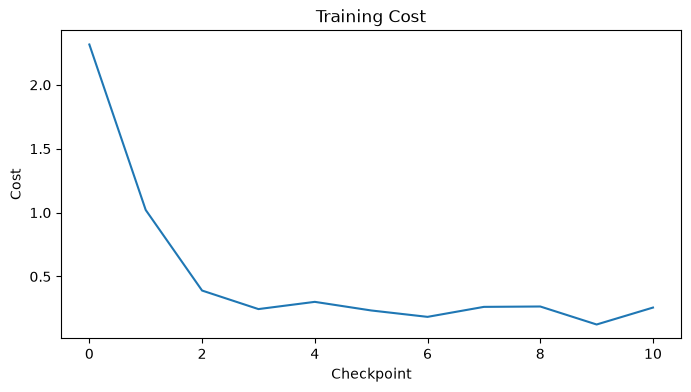

In [23]:
plt.figure(figsize=(8, 4))

plt.plot(range(len(costs)), costs)

plt.xlabel('Checkpoint')
plt.ylabel('Cost')
plt.title('Training Cost')
plt.show()

# Define function for predictions and their accuracy

In [24]:
def predict(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2
    p = np.zeros((1,m))
    
    probas, caches = L_model_forward(X, parameters)
    return np.argmax(probas, axis=0)    

In [25]:
def accuracy(y, y_hat):
    acc = np.sum(y==y_hat)/len(y)
    return acc

# Make predictions on training data, get accuracy

In [26]:
pred_train = predict(train_x, train_y, parameters)

In [27]:
print('Train Accuracy:', round(accuracy(train_y, pred_train) * 100, 2), '%')

Train Accuracy: 93.34 %


# Print confusion matrix and classification report for train predictions

In [28]:
print(confusion_matrix(train_y, pred_train))
print(classification_report(train_y, pred_train, zero_division=0))

[[5659    0   42   12   45    2   21   56   49   37]
 [   0 6601   53   27    8    0    2   10   33    8]
 [   5   12 5725   46   76    0   19   41   28    6]
 [   1   12  149 5741   13    4    8   50  116   37]
 [   2    9   15    2 5726    0   14    6    7   61]
 [  41   21   24  683   50 4133   97   27  243  102]
 [  28    6   41    0   56    9 5718    9   51    0]
 [   1   19   51   24   56    1    2 6024   16   71]
 [   7   37   90   37   78    5   37   10 5477   73]
 [  12   17    1   47  514   10    0   89   60 5199]]
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      5923
           1       0.98      0.98      0.98      6742
           2       0.92      0.96      0.94      5958
           3       0.87      0.94      0.90      6131
           4       0.86      0.98      0.92      5842
           5       0.99      0.76      0.86      5421
           6       0.97      0.97      0.97      5918
           7       0.95      0.96   

# Make predictions on test data, get accuracy

In [29]:
pred_test = predict(test_x, test_y, parameters)

print('Test Accuracy:', round(accuracy(test_y, pred_test) * 100, 2), '%')

Test Accuracy: 92.84 %


# Print confusion matrix and classification report for test predictions

In [30]:
print(confusion_matrix(test_y, pred_test))
print(classification_report(test_y, pred_test, zero_division=0))

[[ 947    0    0    3    7    2    0   10    6    5]
 [   0 1118    5    2    0    0    3    1    6    0]
 [   2    1  988    8   12    0    3    9    7    2]
 [   1    1   23  945    2    1    0   10   22    5]
 [   1    0    6    0  957    0    2    3    2   11]
 [   9    4    2  112    9  674   16    5   48   13]
 [   8    2   11    0   18    4  907    3    4    1]
 [   0    5   20    7    8    0    0  969    2   17]
 [   1    2   11   10   15    0   13    3  908   11]
 [   5    6    1   10   95    0    0    9   12  871]]
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       980
           1       0.98      0.99      0.98      1135
           2       0.93      0.96      0.94      1032
           3       0.86      0.94      0.90      1010
           4       0.85      0.97      0.91       982
           5       0.99      0.76      0.86       892
           6       0.96      0.95      0.95       958
           7       0.95      0.94   

# Plot part of the incorrectly predicted images and append them to list

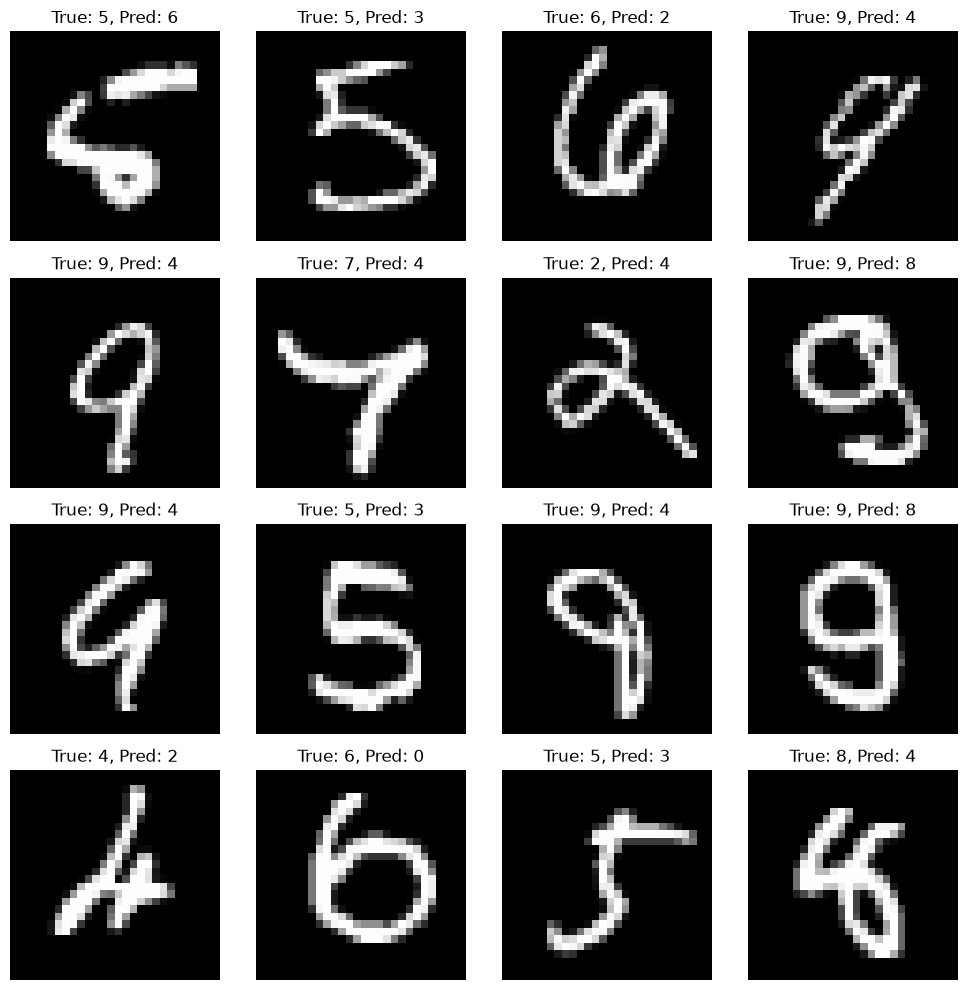

In [31]:
incorrect_list = np.where(pred_test != test_y)[0][:16].tolist()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    if i < len(incorrect_list):
        idx = incorrect_list[i]

        ax.imshow(test_X[idx], cmap='gray')
        ax.set_title(
            f'True: {test_y[idx]}, Pred: {pred_test[idx]}'
        )

    ax.axis('off')

plt.tight_layout()
plt.show()

# Define function for getting derivative of loss with respect to input for saliency maps

In [32]:
def get_saliency_map(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2
    p = np.zeros((1,m))
    
    probas, caches = L_model_forward(X, parameters)
    cost = compute_cost(probas, y)
    grads = L_model_backward(probas, y, caches)
    dy_dx = grads["dA0"]

    return np.argmax(probas, axis=0), dy_dx

# Prepare incorrectly predicted data for saliency maps 

In [33]:
saliency_test = test_x[:, incorrect_list]
saliency_test_y = test_y[incorrect_list]

test_y_one_hot_for_saliency = to_categorical(
    saliency_test_y, num_classes=10
).T

print(saliency_test.shape)
print(test_y_one_hot_for_saliency.shape)

(784, 16)
(10, 16)


# Get predictions and derivative of loss with respect to input

In [34]:
probas, dy_dx = get_saliency_map(
    saliency_test,
    test_y_one_hot_for_saliency,
    parameters
)

# Reshape and normalize results for plot 

In [35]:
dy_dx_one_rs = np.abs(dy_dx).reshape(28, 28, -1)

normalized_tensor = dy_dx_one_rs / (
    np.max(dy_dx_one_rs, axis=(0, 1), keepdims=True) + 1e-8
)

# Apply penalty for smaller values

In [36]:
normalized_tensor_weighted = normalized_tensor ** 2

# The brightest points show the highest impact on loss

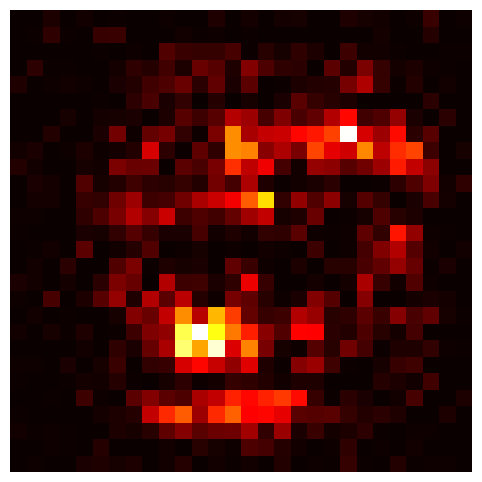

In [37]:
plt.figure(figsize=(6, 6))

plt.imshow(normalized_tensor_weighted[:, :, 0], cmap='hot')

plt.axis('off')
plt.show()

# Darken the prediction images so saliency points become the brightest ones in image

In [38]:
dark_images = test_X[incorrect_list] / 255.0 * 0.3

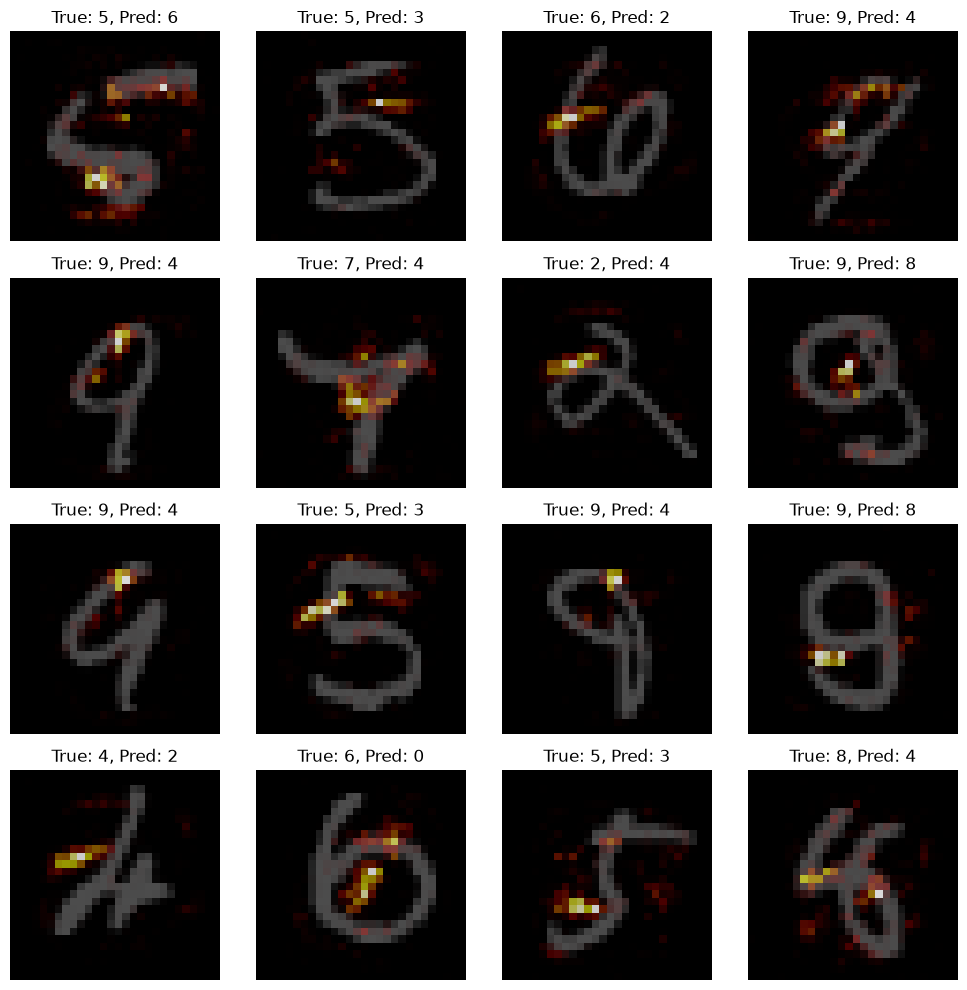

In [39]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    if i < len(incorrect_list):
        ax.imshow(dark_images[i], cmap='gray', vmin=0, vmax=1)

        heat = normalized_tensor_weighted[:, :, i]

        ax.imshow(
            heat,
            cmap='hot',
            alpha=np.clip(heat * 0.8, 0, 0.8),
            vmin=0,
            vmax=1
        )

        ax.set_title(
            f'True: {test_y[incorrect_list[i]]}, '
            f'Pred: {pred_test[incorrect_list[i]]}'
        )

    ax.axis('off')

plt.tight_layout()
plt.show()

### Conclusion

I built a neural network from scratch to recognize handwritten digits. After training, I checked its accuracy on both training and test data. I also looked at some incorrectly classified digits and made saliency maps to see which pixels affected the loss the most.
For me, backpropagation was the hardest part, but it helped me understand how the network updates its weights and learns from mistakes.